In [1]:
import numpy as np
import pandas as pd
from nltk.classify import NaiveBayesClassifier
from nltk.corpus import subjectivity
from nltk.sentiment import SentimentAnalyzer
from nltk.sentiment.util import *

import numpy as np 
import pandas as pd 
#pd.set_option('display.max_colwidth', -1)
from time import time
import re
import string
import os
from pprint import pprint
import collections

import matplotlib.pyplot as plt
import seaborn as sns
sns.set(style="darkgrid")
sns.set(font_scale=1.3)

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.metrics import classification_report

from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
#from sklearn.externals import joblib
import joblib as jb

#import gensim

from nltk.corpus import stopwords
from nltk.stem import PorterStemmer
from nltk.tokenize import word_tokenize

import warnings
warnings.filterwarnings('ignore')

np.random.seed(37)

# import stata_setup
# stata_setup.config('C:/Users/Farid Srouji/Stata15/', 'mp')
# import sys
# sys.path.append("C:/Users/Farid Srouji/Stata15/utilities")
# from pystata import config
# config.init()

In [2]:
# Reading the saved data pickle file
df  = pd.DataFrame()
df = pd.read_pickle('/Users/Farid Srouji/Documents/Research/master/financialmodelingprep/data/pkl/pickled_filtered_lead_para_sp500_clean.pkl', compression=None)
df_sentiment=pd.read_pickle('/Users/Farid Srouji/Documents/Research/master/financialmodelingprep/data/pkl/sentiment.pkl', compression=None)

In [3]:
import pandas as pd
#if you get an error after executing the code, try adding below:
pd.core.common.is_list_like = pd.api.types.is_list_like

import pandas_datareader.data as web
import datetime

start = datetime.datetime(2019, 9, 25)
end = datetime.datetime(2021, 7, 15)
SP500  = pd.DataFrame()

SP500 = web.DataReader(['sp500'], 'fred', start, end)

In [4]:
SP500

,sp500
DATE,
2019-09-25,2984.87
2019-09-26,2977.62
2019-09-27,2961.79
2019-09-30,2976.74
2019-10-01,2940.25
...,...
2021-07-09,4369.55
2021-07-12,4384.63
2021-07-13,4369.21


In [6]:
# df["sp500"] = SP500["sp500"]
# print(SP500[SP500["sp500"].isnull()])
# SP500["sp500"] = pd.to_numeric(SP500["sp500"])
# df["sp500"]=SP500["sp500"].astype(np.float).astype("Int64")
# df["sps"].columns=

In [7]:
df["sp500"]=SP500["sp500"]

In [8]:
df

,close,adj close,articles,sp500
2019-09-25,15.960000,15.960000,FDA Approves Abbott's Low Dose Recharge-Free S...,NaN
2019-09-26,16.070000,16.070000,"FDA Approves Abbott's ""Low Dose,"" Recharge-Fre...",NaN
2019-09-27,17.219999,17.219999,New Data Demonstrate Strong Outcomes for Abbot...,NaN
2019-09-30,16.240000,16.240000,"ParTech, Inc. completed the acquisition of ass...",NaN
2019-10-01,18.559999,18.559999,"Accenture plc Presents at All Day DevOps, Nov-...",NaN
...,...,...,...,...
2021-07-12,16.170000,16.170000,3M Oral Care Introduces Next-Generation Clear ...,NaN
2021-07-13,17.120001,17.120001,3M Announces Upcoming Investor Event. ST. PAUL...,NaN
2021-07-14,16.330000,16.330000,Cybersecurity Executive Rick Driggers Joins Ac...,NaN
2021-07-15,17.010000,17.010000,Air Products Declares Quarterly Dividend. LEHI...,NaN


In [11]:
df["articles"].describe()
# df = df.join(df_sentiment)
# df = df.join(SP500)

df["vix"] = df["adj close"]#.apply(np.int)
df["vix_ln_return"]=np.log(df["vix"]/df["vix"].shift(1))
df['sentiment'] = df[["sentiment"]].apply(pd.to_numeric)
df["sentiment_ewm"]=df["sentiment"].ewm(10).mean()
df["date"]=df.index
# df["sp500"]=SP500.values()
# df['date'] = pd.date_range(start='25/9/2019', periods=len(df), freq='D')
df_part1 = df.loc['2019-09-25':'2020-02-14']
df_part2 = df.loc['2020-02-15':'2020-05-31']
df_part3 = df.loc['2020-06-01':'2021-07-15']

In [12]:
df

,close,adj close,articles,sp500,compound,neg,neu,pos,sentiment,sentiment_complementary,vix,vix_ln_return,sentiment_ewm,date
2019-09-25,15.960000,15.960000,FDA Approves Abbott's Low Dose Recharge-Free S...,NaN,1.0,0.015,0.879,0.106,87.603306,12.396694,15.960000,NaN,87.603306,2019-09-25
2019-09-26,16.070000,16.070000,"FDA Approves Abbott's ""Low Dose,"" Recharge-Fre...",NaN,1.0,0.022,0.859,0.118,84.285714,15.714286,16.070000,0.006869,85.865520,2019-09-26
2019-09-27,17.219999,17.219999,New Data Demonstrate Strong Outcomes for Abbot...,NaN,0.9998,0.033,0.862,0.105,76.086957,23.913043,17.219999,0.069117,82.290879,2019-09-27
2019-09-30,16.240000,16.240000,"ParTech, Inc. completed the acquisition of ass...",NaN,1.0,0.024,0.849,0.127,84.105960,15.894040,16.240000,-0.058594,82.811429,2019-09-30
2019-10-01,18.559999,18.559999,"Accenture plc Presents at All Day DevOps, Nov-...",NaN,0.9999,0.021,0.901,0.078,78.787879,21.212121,18.559999,0.133531,81.846518,2019-10-01
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2021-07-12,16.170000,16.170000,3M Oral Care Introduces Next-Generation Clear ...,NaN,0.9999,0.013,0.848,0.138,91.390728,8.609272,16.170000,-0.000618,88.107165,2021-07-12
2021-07-13,17.120001,17.120001,3M Announces Upcoming Investor Event. ST. PAUL...,NaN,1.0,0.011,0.843,0.146,92.993631,7.006369,17.120001,0.057090,88.551389,2021-07-13
2021-07-14,16.330000,16.330000,Cybersecurity Executive Rick Driggers Joins Ac...,NaN,0.9999,0.01,0.874,0.116,92.063492,7.936508,16.330000,-0.047244,88.870672,2021-07-14
2021-07-15,17.010000,17.010000,Air Products Declares Quarterly Dividend. LEHI...,NaN,1.0,0.016,0.817,0.166,91.208791,8.791209,17.010000,0.040797,89.083228,2021-07-15


In [13]:
train_start_date = '2020-06-01'
train_end_date = '2021-05-31'
test_start_date = '2021-06-01'
test_end_date = '2021-07-15'

train = df_part3.loc[train_start_date : train_end_date]
test = df_part3.loc[test_start_date:test_end_date]

In [14]:
sentiment_score_list = []
for date, row in train.T.iteritems():
    #sentiment_score = np.asarray([df.loc[date, 'compound'],df.loc[date, 'neg'],df.loc[date, 'neu'],df.loc[date, 'pos']])
    sentiment_score = np.asarray([df_part3.loc[date, 'neg'],df_part3.loc[date, 'pos']])
    sentiment_score_list.append(sentiment_score)
numpy_df_train = np.asarray(sentiment_score_list)

In [15]:
sentiment_score_list = []
for date, row in test.T.iteritems():
    #sentiment_score = np.asarray([df.loc[date, 'compound'],df.loc[date, 'neg'],df.loc[date, 'neu'],df.loc[date, 'pos']])
    sentiment_score = np.asarray([df_part3.loc[date, 'neg'],df_part3.loc[date, 'pos']])
    sentiment_score_list.append(sentiment_score)
numpy_df_test = np.asarray(sentiment_score_list)

In [16]:
y_train = pd.DataFrame(train['vix'])
y_test = pd.DataFrame(test['vix'])

In [17]:
from treeinterpreter import treeinterpreter as ti
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import classification_report,confusion_matrix

rf = RandomForestRegressor()
y_train = np.nan_to_num(y_train)
numpy_df_train = np.nan_to_num(numpy_df_train)
rf.fit(numpy_df_train, y_train)

RandomForestRegressor()

In [18]:
prediction, bias, contributions = ti.predict(rf, numpy_df_test)

In [19]:
idx = y_test.index
predictions_df = pd.DataFrame(data=prediction[0:], index = idx, columns=['predicted_vix'] )

In [20]:
train

,close,adj close,articles,sp500,compound,neg,neu,pos,sentiment,sentiment_complementary,vix,vix_ln_return,sentiment_ewm,date
2020-06-01,28.230000,28.230000,Abbvie Submits Regulatory Applications To FDA ...,NaN,0.9994,0.018,0.865,0.117,86.666667,13.333333,28.230000,0.025836,78.231366,2020-06-01
2020-06-02,26.840000,26.840000,Bigfoot Biomedical® Closes Series C Financing ...,NaN,0.999,0.024,0.861,0.114,82.608696,17.391304,26.840000,-0.050492,78.629305,2020-06-02
2020-06-03,25.660000,25.660000,3M Appoints Monish Patolawala As New Chief Fin...,NaN,0.9996,0.021,0.843,0.136,86.624204,13.375796,25.660000,-0.044960,79.356114,2020-06-03
2020-06-04,25.809999,25.809999,Abbvie Says Rinvoq's Safety Profile Was Consis...,NaN,0.9997,0.022,0.847,0.131,85.620915,14.379085,25.809999,0.005829,79.925642,2020-06-04
2020-06-05,24.520000,24.520000,"Abbvie, Harbour Biomed, Utrecht University And...",NaN,0.7187,0.1,0.798,0.101,50.248756,49.751244,24.520000,-0.051273,77.227742,2020-06-05
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2021-05-24,18.400000,18.400000,3M introduces 3M™ Environmental Scrub Sampler ...,NaN,1.0,0.024,0.85,0.126,84.000000,16.000000,18.400000,-0.090854,86.336047,2021-05-24
2021-05-25,18.840000,18.840000,AbbVie Receives European Commission Approval o...,NaN,1.0,0.01,0.83,0.16,94.117647,5.882353,18.840000,0.023632,87.043467,2021-05-25
2021-05-26,17.360001,17.360001,Accenture Acquires Industrie&Co to Help Austra...,NaN,0.9999,0.014,0.863,0.123,89.781022,10.218978,17.360001,-0.081814,87.292336,2021-05-26
2021-05-27,16.740000,16.740000,AMD EPYC™ Processors Accelerate High Performan...,NaN,1.0,0.008,0.824,0.169,95.480226,4.519774,16.740000,-0.036368,88.036692,2021-05-27


i=0
col=sentiment
i=1
col=sp500


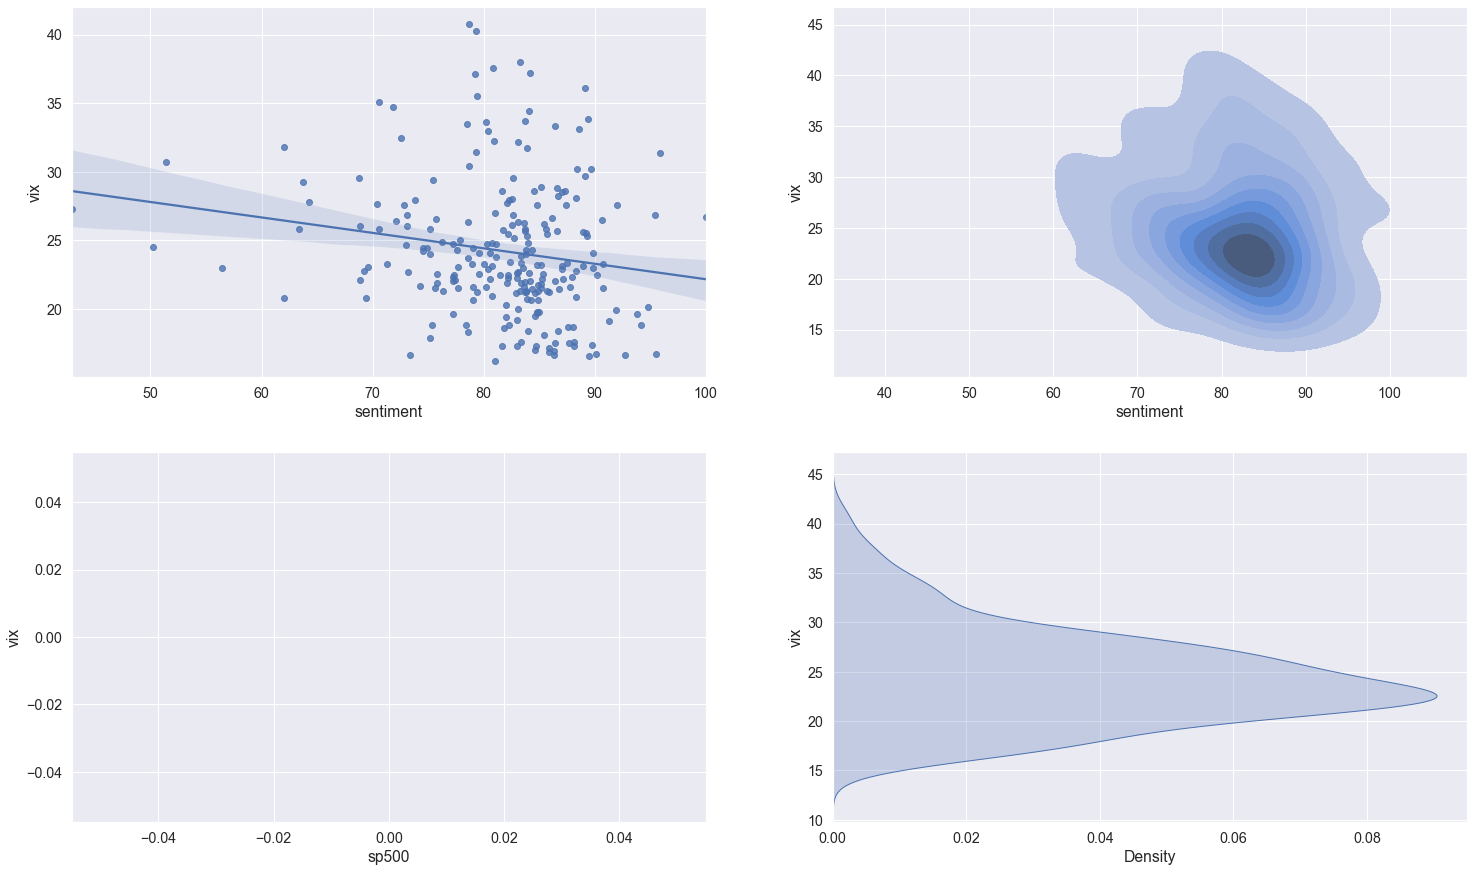

In [21]:
#TEMP
# Columns to plot 
plot_columns = ['sentiment', 'sp500', "Open",]

# plot
fig, axes = plt.subplots(2,2,figsize=(25,15))
for i,col in enumerate(plot_columns):
    print("i="+str(i))
    print("col="+str(col))

    sns.regplot(col,'vix',data=train, ax=axes[i,0]) # regression plot
    sns.kdeplot(train[col],train['vix'],shade=True, ax=axes[i,1]) # kernel density estimate plot

In [22]:
from scipy import stats
def slice_and_anaylze(slice_at):
    # slice dataframe till the given parameter(slice_at)
    
    print(f'Plot from 0 to {slice_at}.')
    mean_by_dtexp = df_part3.groupby('day').mean()['vix']
    mean_by_dtexp = mean_by_dtexp[:slice_at]  # slice
    mean_by_dtexp = pd.DataFrame({'day':mean_by_dtexp.index,
                                  'Mean_of_VIX':mean_by_dtexp.values})  # Convert series to dataframe (for sns plot)
    
    # lmplot
    sns.lmplot(x='day',y='Mean_of_VIX',data=mean_by_dtexp)
    plt.show()

    # correlation test (pearson)
    corr_coef = stats.pearsonr(mean_by_dtexp['day'],mean_by_dtexp['Mean_of_VIX'])
    print('Pearson correlation test')
    print('='*50)
    print('correlation coefficient:',corr_coef[0])
    print('2-tailed p-value:', corr_coef[1])

In [23]:
slice_and_anaylze(20)

Plot from 0 to 20.


KeyError: 'day'

In [ ]:

# 2017 onwards
last_year = df_part3.loc[df_part3['year'] > 2021]
g = last_year.groupby(["date"])
monthly_averages = g.aggregate({"open": np.mean, "high": np.mean, "low": np.mean, "close":np.mean})
monthly_averages.reset_index(level=0, inplace=True)

monthly_averages.dtypes


trace = go.Candlestick(x=monthly_averages['date'],
                       open=monthly_averages['open'].values.tolist(),
                       high=monthly_averages['high'].values.tolist(),
                       low=monthly_averages['low'].values.tolist(),
                       close=monthly_averages['close'].values.tolist(),
                      increasing=dict(line=dict(color= '#58FA58')),
                decreasing=dict(line=dict(color= '#FA5858')))


layout = {
    'title': 'Amazon Historical Price <br> <i>A closer look to the upward trend </i>',
    'xaxis': {'title': 'Date',
             'rangeslider': {'visible': False}},
    'yaxis': {'title': 'Stock Price (USD$)'}
}


data = [trace]

fig = go.Figure(data=data, layout=layout)
iplot(fig, filename='simple_ohlc')

In [ ]:
# Correlation matrix
corr = train[plot_columns].corr()

mask = np.zeros_like(corr)
for i in range(mask.shape[0]):
    mask[i,i]=True
plt.figure(figsize=(12,5))
sns.heatmap(corr,annot=True,mask=mask,cmap='coolwarm',vmin=-1,vmax=1)
plt.show()

In [ ]:
# Plot variables with high correlation coefficient

def cor_reg_kde(x,y,data):
    # Correlation coefficient
    print('correlation coefficient:',corr.loc[x,y])
    
    # Subplot adjust
    plt.subplots_adjust(wspace=0.5)
    
    # Plot (regression and kernel density)
    fig,(ax1,ax2) = plt.subplots(1,2,figsize=(10,5))
    sns.regplot(x,y,data=data,ax=ax1)
    sns.kdeplot(data[x],data[y],shade=True,ax=ax2)
    
cor_reg_kde('sentiment','vix',train)
# cor_reg_kde('Indiv_Put_Netbuying_Quantity','Open_interest',train_org)
# cor_reg_kde('Indiv_Put_Netbuying_Quantity','Indiv_Call_Netbuying_Quantity',train_org)
# cor_reg_kde('Indiv_Call_Netbuying_Quantity','Open_interest',train_org)


In [ ]:
lr.classes_

In [ ]:
lr.coef_[0]

# RandomForestRegressor

In [ ]:
from treeinterpreter import treeinterpreter as ti
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LogisticRegression
from datetime import datetime, timedelta

# average_upcoming_5_days_predicted += predictions_df.loc[temp_date, 'VIX']
# # Converting string to date time
# temp_date = datetime.strptime(temp_date, "%Y-%m-%d").date()
# # Adding one day from date time
# difference = temp_date + timedelta(days=1)
# # Converting again date time to string
# temp_date = difference.strftime('%Y-%m-%d')
        
# start_year = datetime.strptime(train_start_date, "%Y-%m-%d").date().month

prediction_list = []
# Splitting the training and testing data
train_start_date = '2020-06-01'
train_end_date = '2021-05-31'
test_start_date = '2021-06-01'
test_end_date = '2021-07-15'
train = df.loc[train_start_date : train_end_date]
test = df.loc[test_start_date:test_end_date]

# Calculating the sentiment score
sentiment_score_list = []
for date, row in train.T.iteritems():
    sentiment_score = np.asarray([df.loc[date, 'compound'],df.loc[date, 'neg'],df.loc[date, 'neu'],df.loc[date, 'pos']])
    #sentiment_score = np.asarray([df.loc[date, 'neg'],df.loc[date, 'pos']])
    sentiment_score_list.append(sentiment_score)
numpy_df_train = np.asarray(sentiment_score_list)
sentiment_score_list = []
for date, row in test.T.iteritems():
    sentiment_score = np.asarray([df.loc[date, 'compound'],df.loc[date, 'neg'],df.loc[date, 'neu'],df.loc[date, 'pos']])
    #sentiment_score = np.asarray([df.loc[date, 'neg'],df.loc[date, 'pos']])
    sentiment_score_list.append(sentiment_score)
numpy_df_test = np.asarray(sentiment_score_list)
# Generating models
rf = RandomForestRegressor(random_state=0)
rf.fit(numpy_df_train, train['VIX'])
#print rf

prediction, bias, contributions = ti.predict(rf, numpy_df_test)
prediction_list.append(prediction)
#print train_start_date + ' ' + train_end_date + ' ' + test_start_date + ' ' + test_end_date
idx = pd.date_range(test_start_date, test_end_date)
#print year
predictions_df_list = pd.DataFrame(data=prediction[0:], index = idx, columns=['VIX'])

difference_test_predicted_VIX = offset_value(test_start_date, test, predictions_df_list)
# Adding offset to all the advpredictions_df VIX values
predictions_df_list['VIX'] = predictions_df_list['VIX'] + difference_test_predicted_VIX
predictions_df_list

# Smoothing the plot
predictions_df_list['ewm'] = predictions_df_list["VIX"].ewm(span=60).mean()
predictions_df_list['actual_value'] = test['VIX']
predictions_df_list['actual_value_ewm'] = predictions_df_list["actual_value"].ewm(span=10).mean()
# Changing column names
predictions_df_list.columns = ['predicted_VIX', 'average_predicted_VIX', 'actual_VIX', 'average_actual_VIX']
predictions_df_list.plot()
predictions_df_list_average = predictions_df_list[['average_predicted_VIX', 'average_actual_VIX']]
predictions_df_list_average.plot(title='RandomForestRegressor', xlabel="Dates", ylabel="VIX")

#     predictions_df_list.show()


In [ ]:
# from IPython.display import Image  
# dot_data = tree.export_graphviz(rf, out_file=None, 
#                      feature_names=['comp', 'neg', 'neu', 'pos'],  
#                      class_names=iris.target_names,  
#                      filled=True, rounded=True,  
#                      special_characters=True)  
# graph = pydotplus.graph_from_dot_data(dot_data)  
# Image(graph.create_png())

# MLP Classifier

In [ ]:
from sklearn.neural_network import MLPClassifier
from datetime import datetime, timedelta

# average_upcoming_5_days_predicted += predictions_df.loc[temp_date, 'VIX']
# # Converting string to date time
# temp_date = datetime.strptime(temp_date, "%Y-%m-%d").date()
# # Adding one day from date time
# difference = temp_date + timedelta(days=1)
# # Converting again date time to string
# temp_date = difference.strftime('%Y-%m-%d')
        
# start_year = datetime.strptime(train_start_date, "%Y-%m-%d").date().month

prediction_list = []
# Splitting the training and testing data
train_start_date = '2020-06-01'
train_end_date = '2021-05-31'
test_start_date = '2021-06-01'
test_end_date = '2021-07-15'
train = df.loc[train_start_date : train_end_date]
test = df.loc[test_start_date:test_end_date]

# Calculating the sentiment score
sentiment_score_list = []
for date, row in train.T.iteritems():
    sentiment_score = np.asarray([df.loc[date, 'compound'],df.loc[date, 'neg'],df.loc[date, 'neu'],df.loc[date, 'pos']])
    #sentiment_score = np.asarray([df.loc[date, 'neg'],df.loc[date, 'pos']])
    sentiment_score_list.append(sentiment_score)
numpy_df_train = np.asarray(sentiment_score_list)
sentiment_score_list = []
for date, row in test.T.iteritems():
    sentiment_score = np.asarray([df.loc[date, 'compound'],df.loc[date, 'neg'],df.loc[date, 'neu'],df.loc[date, 'pos']])
    #sentiment_score = np.asarray([df.loc[date, 'neg'],df.loc[date, 'pos']])
    sentiment_score_list.append(sentiment_score)
numpy_df_test = np.asarray(sentiment_score_list)

# Generating models
mlpc = MLPClassifier(hidden_layer_sizes=(100, 200, 100), activation='relu', 
                        solver='lbfgs', alpha=0.005, learning_rate_init = 0.001, shuffle=False) # span = 20 # best 1
mlpc.fit(numpy_df_train, train['VIX'])   
prediction = mlpc.predict(numpy_df_test)

prediction_list.append(prediction)
#print train_start_date + ' ' + train_end_date + ' ' + test_start_date + ' ' + test_end_date
idx = pd.date_range(test_start_date, test_end_date)
#print year
predictions_df_list = pd.DataFrame(data=prediction[0:], index = idx, columns=['VIX'])

difference_test_predicted_VIX = offset_value(test_start_date, test, predictions_df_list)
# Adding offset to all the advpredictions_df VIX values
predictions_df_list['VIX'] = predictions_df_list['VIX'] + difference_test_predicted_VIX
predictions_df_list

# Smoothing the plot
predictions_df_list['ewm'] = predictions_df_list["VIX"].ewm(span=20).mean()
predictions_df_list['actual_value'] = test['VIX']
predictions_df_list['actual_value_ewm'] = predictions_df_list["actual_value"].ewm(span=20).mean()
# Changing column names
predictions_df_list.columns = ['predicted_VIX', 'average_predicted_VIX', 'actual_VIX', 'average_actual_VIX']
predictions_df_list.plot()
predictions_df_list_average = predictions_df_list[['average_predicted_VIX', 'average_actual_VIX']]
predictions_df_list_average.plot(title='MLP Classifier', xlabel="Dates", ylabel="VIX")

#     predictions_df_list.show()
    

In [ ]:
mlpc = MLPClassifier(hidden_layer_sizes=(100, 200, 100), activation='tanh', 
                         solver='lbfgs', alpha=0.010, learning_rate_init = 0.001, shuffle=False)
mlpc = MLPClassifier(hidden_layer_sizes=(100, 200, 100), activation='relu', 
                         solver='lbfgs', alpha=0.010, learning_rate_init = 0.001, shuffle=False) # span = 20
mlpc = MLPClassifier(hidden_layer_sizes=(100, 200, 100), activation='relu', 
                         solver='lbfgs', alpha=0.005, learning_rate_init = 0.001, shuffle=False) # span = 20 # best 1
mlpc = MLPClassifier(hidden_layer_sizes=(100, 200, 50), activation='relu', 
                         solver='lbfgs', alpha=0.005, learning_rate_init = 0.001, shuffle=False)
                     

In [ ]:
# checking the performance of training data itself
prediction, bias, contributions = ti.predict(rf, numpy_df_train)
idx = pd.date_range(train_start_date, train_end_date)
predictions_df1 = pd.DataFrame(data=prediction[0:], index = idx, columns=['VIX'])
predictions_df1.plot()
train['VIX'].plot()

In [ ]:
#https://www.statsmodels.org/stable/generated/statsmodels.tsa.arima_model.ARMAResults.plot_predict.html
import statsmodels.api as sm
import matplotlib.pyplot as plt
import pandas as pd

# dta = sm.datasets.sunspots.load_pandas().data[['SUNACTIVITY']]
# dta.index = pd.date_range(start='1700', end='2009', freq='A')
# print(type(dta))
# print(dta)
dta=df_part3["VIX"]
dta2=df_part3["sentiment"]
res = sm.tsa.ARMA(dta, (3, 0)).fit()
fig, ax = plt.subplots()
ax = dta.loc['2020-06-01':].plot(ax=ax)
fig = res.plot_predict('2021-07-15', '2021-08-15', dynamic=True, ax=ax,
                        plot_insample=False)
plt.title("ARMA")
plt.show()

In [ ]:
# VAR example
from statsmodels.tsa.vector_ar.var_model import VAR
from random import random
# contrived dataset with dependency
data = df_part3["sentiment"].tolist()
# data = list(df_part3["sentiment","VIX"])

# fit model
model = VAR(data)
model_fit = model.fit()
# make prediction
yhat = model_fit.forecast(model_fit.y, steps=1)

# VAR example
from statsmodels.tsa.vector_ar.var_model import VAR
from random import random
# contrived dataset with dependency
data = list()
for i in range(100):
    v1 = i + random()
    v2 = v1 + random()
    row = [v1, v2]
    data.append(row)
# fit model
model = VAR(data)
model_fit = model.fit()
# make prediction
yhat = model_fit.forecast(model_fit.y, steps=1)


In [ ]:

# VAR example
from statsmodels.tsa.vector_ar.var_model import VAR
from random import random
# contrived dataset with dependency
data = list()
for i in range(100):
    v1 = i + random()
    v2 = v1 + random()
    row = [v1, v2]
    data.append(row)
# fit model
model = VAR(data)
model_fit = model.fit()
# make prediction
yhat = model_fit.forecast(model_fit.y, steps=1)
print(yhat)
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
# VAR example
from statsmodels.tsa.vector_ar.var_model import VAR
from random import random
# contrived dataset with dependency
data = list()
for i in range(100):
    v1 = i + random()
    v2 = v1 + random()
    row = [v1, v2]
    data.append(row)
# fit model
model = VAR(data)
model_fit = model.fit()
# make prediction
yhat = model_fit.forecast(model_fit.y, steps=1)
print(yhat)